In [1]:
import pandas as pd
import numpy as np
import random
from datetime import datetime , timedelta

In [2]:
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
random.seed(42)
np.random.seed(42)

restaurant_data = []

locations = [
    "T Nagar", "Anna Nagar", "Velachery",
    "Adyar", "Tambaram", "Guindy",
    "Porur", "Mylapore", "OMR", "Chromepet"
]

for i in range(1, 51):

    restaurant_data.append({
        "restaurant_id": i,
        "restaurant_name": f"Restaurant_{i}",
        "location": random.choice(locations),
        "food_type": random.choice([
            "Veg", "Non-Veg", "Both"
        ]),
        "daily_capacity": random.randint(50, 500)
    })

restaurants = pd.DataFrame(restaurant_data)

restaurants.to_csv("restaurants.csv", index=False)

print("Restaurant Dataset Created Successfully!")

print(restaurants.head())

Restaurant Dataset Created Successfully!
   restaurant_id restaurant_name    location food_type  daily_capacity
0              1    Restaurant_1  Anna Nagar       Veg             429
1              2    Restaurant_2    Tambaram       Veg             164
2              3    Restaurant_3   Velachery      Both             102
3              4    Restaurant_4         OMR       Veg             352
4              5    Restaurant_5       Porur       Veg              65


In [4]:
ngo_data = []

for i in range(1, 11):

    ngo_data.append({
        "ngo_id": i,
        "ngo_name": f"NGO_{i}",
        "location": locations[i-1],
        "daily_requirement": random.randint(50, 300),
        "food_preference": random.choice([
            "Veg", "Non-Veg", "Both"
        ])
    })

ngos = pd.DataFrame(ngo_data)

ngos.to_csv("ngos.csv", index=False)

print("NGO Dataset Created Successfully!")

print(ngos.head())

NGO Dataset Created Successfully!
   ngo_id ngo_name    location  daily_requirement food_preference
0       1    NGO_1     T Nagar                185         Non-Veg
1       2    NGO_2  Anna Nagar                298            Both
2       3    NGO_3   Velachery                270             Veg
3       4    NGO_4       Adyar                224            Both
4       5    NGO_5    Tambaram                 79            Both


In [5]:
food_data = []

food_items = [
    "Rice", "Idli", "Dosa", "Chapati",
    "Biryani", "Sambar Rice",
    "Curd Rice", "Fried Rice"
]

for i in range(1, 501):

    restaurant_id = random.randint(1, 50)

    prepared = random.randint(50, 300)

    sold = random.randint(20, prepared)

    surplus = prepared - sold

    food_data.append({
        "surplus_id": i,
        "restaurant_id": restaurant_id,
        "date": (
            datetime(2026, 1, 1)
            + timedelta(days=random.randint(0, 180))
        ).strftime("%Y-%m-%d"),
        "food_item": random.choice(food_items),
        "food_prepared": prepared,
        "food_sold": sold,
        "surplus_quantity": surplus,
        "expiry_hours": random.randint(2, 12)
    })

food_surplus = pd.DataFrame(food_data)

food_surplus.to_csv(
    "food_surplus.csv",
    index=False
)

print("Food Surplus Dataset Created Successfully!")

print(food_surplus.head())

Food Surplus Dataset Created Successfully!
   surplus_id  restaurant_id        date    food_item  food_prepared  \
0           1             11  2026-03-09         Dosa            166   
1           2              7  2026-03-18      Chapati            272   
2           3             24  2026-05-19         Rice            245   
3           4             21  2026-01-29  Sambar Rice            175   
4           5             16  2026-05-26         Idli             64   

   food_sold  surplus_quantity  expiry_hours  
0         20               146            10  
1        180                92             4  
2         61               184            11  
3         24               151             6  
4         35                29             3  


In [6]:
print("Total Restaurants:", len(restaurants))

print("Total NGOs:", len(ngos))

print("Total Food Surplus Records:", len(food_surplus))

print("\nTotal Surplus Food:",
      food_surplus["surplus_quantity"].sum())

print("\nAverage Surplus Food:",
      food_surplus["surplus_quantity"].mean())

Total Restaurants: 50
Total NGOs: 10
Total Food Surplus Records: 500

Total Surplus Food: 39774

Average Surplus Food: 79.548


In [7]:
import os
print(os.getcwd())

C:\Users\acer


In [8]:
restaurants = pd.read_csv(r"C:\Users\acer\restaurants.csv")
ngos = pd.read_csv(r"C:\Users\acer\ngos.csv")
food_surplus = pd.read_csv(r"C:\Users\acer\food_surplus.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [9]:
print("Restaurant Missing Values:")
print(restaurants.isnull().sum())

print("\nNGO Missing Values:")
print(ngos.isnull().sum())

print("\nFood Surplus Missing Values:")
print(food_surplus.isnull().sum())

Restaurant Missing Values:
restaurant_id      0
restaurant_name    0
location           0
food_type          0
daily_capacity     0
dtype: int64

NGO Missing Values:
ngo_id               0
ngo_name             0
location             0
daily_requirement    0
food_preference      0
dtype: int64

Food Surplus Missing Values:
surplus_id          0
restaurant_id       0
date                0
food_item           0
food_prepared       0
food_sold           0
surplus_quantity    0
expiry_hours        0
dtype: int64


In [10]:
print("Restaurant Duplicates:",
      restaurants.duplicated().sum())

print("NGO Duplicates:",
      ngos.duplicated().sum())

print("Food Surplus Duplicates:",
      food_surplus.duplicated().sum())

Restaurant Duplicates: 0
NGO Duplicates: 0
Food Surplus Duplicates: 0


In [11]:
print("Restaurant Data Types:")
print(restaurants.dtypes)

print("\nNGO Data Types:")
print(ngos.dtypes)

print("\nFood Surplus Data Types:")
print(food_surplus.dtypes)

Restaurant Data Types:
restaurant_id      int64
restaurant_name      str
location             str
food_type            str
daily_capacity     int64
dtype: object

NGO Data Types:
ngo_id               int64
ngo_name               str
location               str
daily_requirement    int64
food_preference        str
dtype: object

Food Surplus Data Types:
surplus_id          int64
restaurant_id       int64
date                  str
food_item             str
food_prepared       int64
food_sold           int64
surplus_quantity    int64
expiry_hours        int64
dtype: object


In [12]:
food_surplus["date"] = pd.to_datetime(
    food_surplus["date"]
)

print(food_surplus.dtypes)

surplus_id                   int64
restaurant_id                int64
date                datetime64[us]
food_item                      str
food_prepared                int64
food_sold                    int64
surplus_quantity             int64
expiry_hours                 int64
dtype: object


In [13]:
print("Negative Surplus:",
      (food_surplus["surplus_quantity"] < 0).sum())

print("Sold More Than Prepared:",
      (food_surplus["food_sold"] >
       food_surplus["food_prepared"]).sum())

print("Invalid Expiry Hours:",
      (food_surplus["expiry_hours"] <= 0).sum())

Negative Surplus: 0
Sold More Than Prepared: 0
Invalid Expiry Hours: 0


In [14]:
restaurants.to_csv(
    r"C:\Users\acer\cleaned_restaurants.csv",
    index=False
)

ngos.to_csv(
    r"C:\Users\acer\cleaned_ngos.csv",
    index=False
)

food_surplus.to_csv(
    r"C:\Users\acer\cleaned_food_surplus.csv",
    index=False
)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!


In [15]:
total_prepared = food_surplus["food_prepared"].sum()

total_sold = food_surplus["food_sold"].sum()

total_surplus = food_surplus["surplus_quantity"].sum()

surplus_percentage = (total_surplus / total_prepared) * 100

print("Total Food Prepared:", total_prepared)

print("Total Food Sold:", total_sold)

print("Total Surplus Food:", total_surplus)

print("Surplus Percentage:", round(surplus_percentage, 2), "%")

Total Food Prepared: 89578
Total Food Sold: 49804
Total Surplus Food: 39774
Surplus Percentage: 44.4 %


In [16]:
restaurant_analysis = food_surplus.groupby(
    "restaurant_id"
)["surplus_quantity"].sum().reset_index()

restaurant_analysis = restaurant_analysis.merge(
    restaurants[["restaurant_id", "restaurant_name"]],
    on="restaurant_id",
    how="left"
)

top_restaurants = restaurant_analysis.sort_values(
    by="surplus_quantity",
    ascending=False
).head(10)

print(top_restaurants)

    restaurant_id  surplus_quantity restaurant_name
13             14              1486   Restaurant_14
41             42              1383   Restaurant_42
6               7              1371    Restaurant_7
19             20              1358   Restaurant_20
28             29              1323   Restaurant_29
48             49              1318   Restaurant_49
35             36              1210   Restaurant_36
29             30              1184   Restaurant_30
22             23              1115   Restaurant_23
47             48              1097   Restaurant_48


In [17]:
food_analysis = food_surplus.groupby(
    "food_item"
)["surplus_quantity"].sum().reset_index()

food_analysis = food_analysis.sort_values(
    by="surplus_quantity",
    ascending=False
)

print(food_analysis)

     food_item  surplus_quantity
0      Biryani              5938
2    Curd Rice              5627
4   Fried Rice              5381
1      Chapati              5231
5         Idli              4907
7  Sambar Rice              4449
3         Dosa              4307
6         Rice              3934


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Visualization libraries imported successfully!


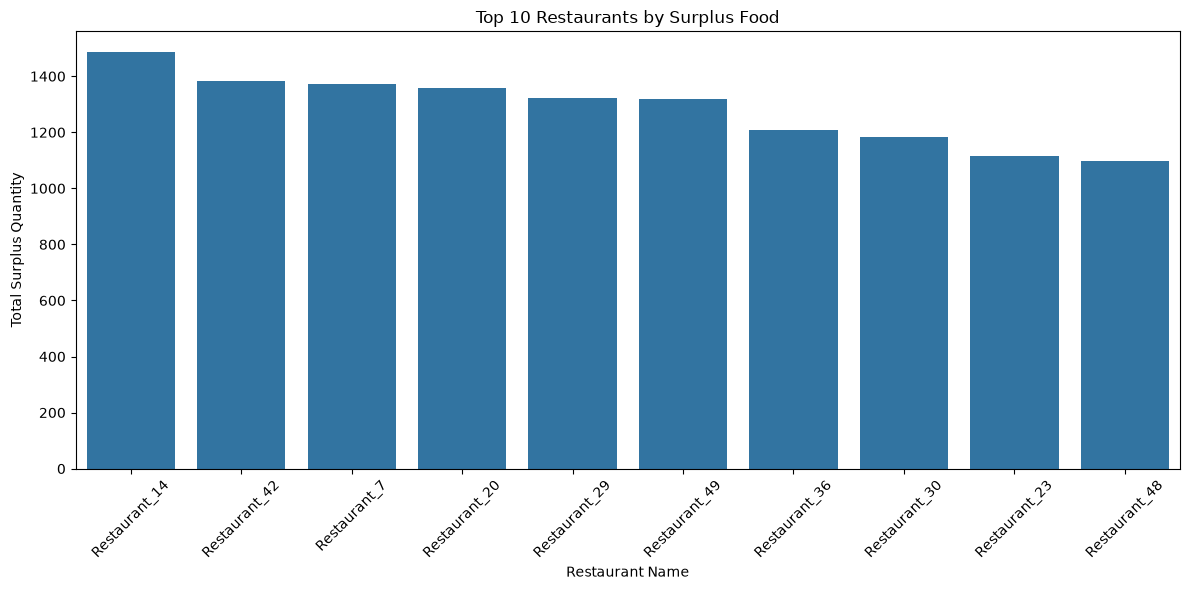

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_restaurants,
    x="restaurant_name",
    y="surplus_quantity"
)

plt.title("Top 10 Restaurants by Surplus Food")

plt.xlabel("Restaurant Name")

plt.ylabel("Total Surplus Quantity")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

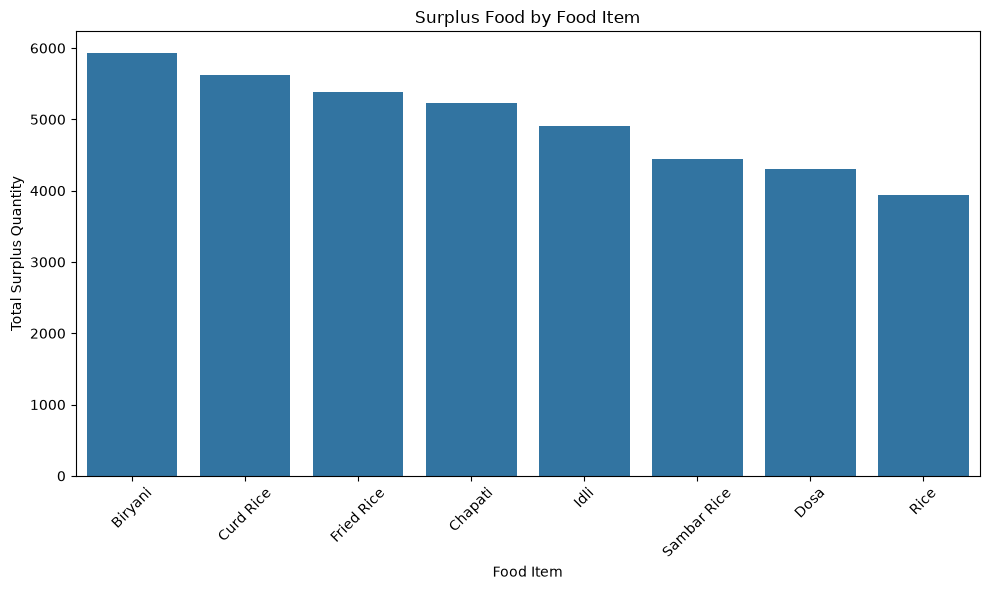

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=food_analysis,
    x="food_item",
    y="surplus_quantity"
)

plt.title("Surplus Food by Food Item")

plt.xlabel("Food Item")

plt.ylabel("Total Surplus Quantity")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [21]:
location_data = food_surplus.merge(
    restaurants[["restaurant_id", "location"]],
    on="restaurant_id",
    how="left"
)

location_analysis = location_data.groupby(
    "location"
)["surplus_quantity"].sum().reset_index()

location_analysis = location_analysis.sort_values(
    by="surplus_quantity",
    ascending=False
)

print(location_analysis)

     location  surplus_quantity
5         OMR              6407
1  Anna Nagar              4891
2   Chromepet              4613
9   Velachery              4541
3      Guindy              4509
6       Porur              4444
8    Tambaram              4227
0       Adyar              2942
7     T Nagar              2436
4    Mylapore               764


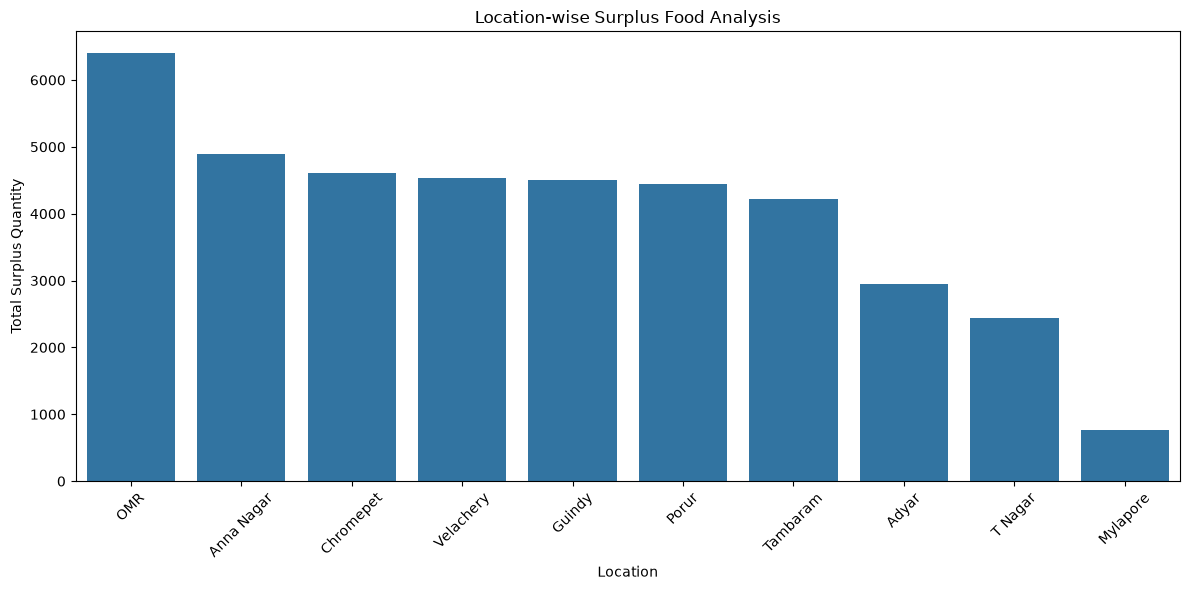

In [22]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=location_analysis,
    x="location",
    y="surplus_quantity"
)

plt.title("Location-wise Surplus Food Analysis")

plt.xlabel("Location")

plt.ylabel("Total Surplus Quantity")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [23]:
top_restaurants.to_csv(
    r"C:\Users\acer\top_restaurants.csv",
    index=False
)

food_analysis.to_csv(
    r"C:\Users\acer\food_analysis.csv",
    index=False
)

location_analysis.to_csv(
    r"C:\Users\acer\location_analysis.csv",
    index=False
)

print("EDA Analysis Files Saved Successfully!")

EDA Analysis Files Saved Successfully!


In [24]:
print("Total Surplus Food:",
      food_surplus["surplus_quantity"].sum())

print("Number of Records:", len(food_surplus))

print("Highest Surplus in One Record:",
      food_surplus["surplus_quantity"].max())

Total Surplus Food: 39774
Number of Records: 500
Highest Surplus in One Record: 266


In [25]:
donation_data = food_surplus.merge(
    restaurants[
        ["restaurant_id", "restaurant_name",
         "location", "food_type"]
    ],
    on="restaurant_id",
    how="left"
)

print("Donation Data Created Successfully!")

print(donation_data.head())

Donation Data Created Successfully!
   surplus_id  restaurant_id       date    food_item  food_prepared  \
0           1             11 2026-03-09         Dosa            166   
1           2              7 2026-03-18      Chapati            272   
2           3             24 2026-05-19         Rice            245   
3           4             21 2026-01-29  Sambar Rice            175   
4           5             16 2026-05-26         Idli             64   

   food_sold  surplus_quantity  expiry_hours restaurant_name location  \
0         20               146            10   Restaurant_11  T Nagar   
1        180                92             4    Restaurant_7      OMR   
2         61               184            11   Restaurant_24    Adyar   
3         24               151             6   Restaurant_21    Adyar   
4         35                29             3   Restaurant_16   Guindy   

  food_type  
0       Veg  
1      Both  
2       Veg  
3      Both  
4      Both  


In [26]:
donation_matches = []

for _, food in donation_data.iterrows():

    # Only consider records with available surplus
    if food["surplus_quantity"] <= 0:
        continue

    # Find NGOs in the same location
    matching_ngos = ngos[
        ngos["location"] == food["location"]
    ]

    # Check food preferences
    matching_ngos = matching_ngos[
        (matching_ngos["food_preference"] == "Both") |
        (matching_ngos["food_preference"] == food["food_type"]) |
        (food["food_type"] == "Both")
    ]

    for _, ngo in matching_ngos.iterrows():

        donation_quantity = min(
            food["surplus_quantity"],
            ngo["daily_requirement"]
        )

        donation_matches.append({
            "surplus_id": food["surplus_id"],
            "restaurant_name": food["restaurant_name"],
            "restaurant_location": food["location"],
            "food_item": food["food_item"],
            "surplus_quantity": food["surplus_quantity"],
            "ngo_name": ngo["ngo_name"],
            "ngo_location": ngo["location"],
            "donation_quantity": donation_quantity,
            "expiry_hours": food["expiry_hours"]
        })

donation_matches_df = pd.DataFrame(donation_matches)

print("Potential Donation Matches Created!")

print(donation_matches_df.head())

Potential Donation Matches Created!
   surplus_id restaurant_name restaurant_location    food_item  \
0           2    Restaurant_7                 OMR      Chapati   
1           3   Restaurant_24               Adyar         Rice   
2           4   Restaurant_21               Adyar  Sambar Rice   
3           5   Restaurant_16              Guindy         Idli   
4           6   Restaurant_47          Anna Nagar         Dosa   

   surplus_quantity ngo_name ngo_location  donation_quantity  expiry_hours  
0                92    NGO_9          OMR                 92             4  
1               184    NGO_4        Adyar                184            11  
2               151    NGO_4        Adyar                151             6  
3                29    NGO_6       Guindy                 29             3  
4               137    NGO_2   Anna Nagar                137             4  


In [27]:
print("Total Potential Matches:", len(donation_matches_df))

print("\nFirst 10 Potential Matches:")

print(donation_matches_df.head(10))

Total Potential Matches: 436

First 10 Potential Matches:
   surplus_id restaurant_name restaurant_location    food_item  \
0           2    Restaurant_7                 OMR      Chapati   
1           3   Restaurant_24               Adyar         Rice   
2           4   Restaurant_21               Adyar  Sambar Rice   
3           5   Restaurant_16              Guindy         Idli   
4           6   Restaurant_47          Anna Nagar         Dosa   
5           7   Restaurant_43           Chromepet      Biryani   
6           8   Restaurant_39               Porur      Chapati   
7           9   Restaurant_26              Guindy   Fried Rice   
8          10   Restaurant_29          Anna Nagar         Idli   
9          11    Restaurant_2            Tambaram      Chapati   

   surplus_quantity ngo_name ngo_location  donation_quantity  expiry_hours  
0                92    NGO_9          OMR                 92             4  
1               184    NGO_4        Adyar                184 

In [28]:
donation_matches_df.to_csv(
    r"C:\Users\acer\donation_matches.csv",
    index=False
)

print("Donation Matching Results Saved Successfully!")

Donation Matching Results Saved Successfully!


In [29]:
# Create NGO requirements
ngo_capacity = {
    row["ngo_id"]: row["daily_requirement"]
    for _, row in ngos.iterrows()
}

# Create allocation list
allocations = []

# Process food records by date
sorted_food = donation_data.sort_values(
    by=["date", "expiry_hours"]
)

# Reset NGO capacity each day
current_date = None

for _, food in sorted_food.iterrows():

    if current_date != food["date"]:

        current_date = food["date"]

        ngo_capacity = {
            row["ngo_id"]: row["daily_requirement"]
            for _, row in ngos.iterrows()
        }

    remaining_food = food["surplus_quantity"]

    # Find NGOs in the same location
    eligible_ngos = ngos[
        ngos["location"] == food["location"]
    ]

    # Check food preference
    eligible_ngos = eligible_ngos[
        (eligible_ngos["food_preference"] == "Both") |
        (eligible_ngos["food_preference"] == food["food_type"]) |
        (food["food_type"] == "Both")
    ]

    for _, ngo in eligible_ngos.iterrows():

        ngo_id = ngo["ngo_id"]

        if remaining_food <= 0:
            break

        available_capacity = ngo_capacity[ngo_id]

        donation_quantity = min(
            remaining_food,
            available_capacity
        )

        if donation_quantity > 0:

            allocations.append({
                "date": food["date"],
                "surplus_id": food["surplus_id"],
                "restaurant_id": food["restaurant_id"],
                "restaurant_name": food["restaurant_name"],
                "ngo_id": ngo_id,
                "ngo_name": ngo["ngo_name"],
                "food_item": food["food_item"],
                "allocated_quantity": donation_quantity
            })

            remaining_food -= donation_quantity

            ngo_capacity[ngo_id] -= donation_quantity

allocation_df = pd.DataFrame(allocations)

print("Smart Donation Allocation Completed!")

print(allocation_df.head())

Smart Donation Allocation Completed!
        date  surplus_id  restaurant_id restaurant_name  ngo_id ngo_name  \
0 2026-01-01          60              3    Restaurant_3       3    NGO_3   
1 2026-01-02         411             21   Restaurant_21       4    NGO_4   
2 2026-01-02         495             24   Restaurant_24       4    NGO_4   
3 2026-01-07         332             18   Restaurant_18       9    NGO_9   
4 2026-01-07          99             20   Restaurant_20      10   NGO_10   

  food_item  allocated_quantity  
0   Chapati                 100  
1   Biryani                 142  
2   Biryani                  52  
3      Dosa                  79  
4   Biryani                  20  


In [30]:
total_surplus = food_surplus["surplus_quantity"].sum()

total_allocated = allocation_df[
    "allocated_quantity"
].sum()

remaining_surplus = total_surplus - total_allocated

allocation_percentage = (
    total_allocated / total_surplus
) * 100

print("Total Surplus Food:", total_surplus)

print("Total Allocated Food:", total_allocated)

print("Remaining Surplus Food:", remaining_surplus)

print(
    "Allocation Percentage:",
    round(allocation_percentage, 2), "%"
)

Total Surplus Food: 39774
Total Allocated Food: 31046
Remaining Surplus Food: 8728
Allocation Percentage: 78.06 %


In [31]:
ngo_analysis = allocation_df.groupby(
    "ngo_name"
)["allocated_quantity"].sum().reset_index()

ngo_analysis = ngo_analysis.sort_values(
    by="allocated_quantity",
    ascending=False
)

print(ngo_analysis)

  ngo_name  allocated_quantity
2    NGO_2                4882
6    NGO_6                4497
3    NGO_3                4338
7    NGO_7                3440
9    NGO_9                3435
4    NGO_4                2821
1   NGO_10                2755
5    NGO_5                2429
0    NGO_1                1685
8    NGO_8                 764


In [32]:
allocation_df.to_csv(
    r"C:\Users\acer\donation_allocations.csv",
    index=False
)

ngo_analysis.to_csv(
    r"C:\Users\acer\ngo_analysis.csv",
    index=False
)

print("Allocation Files Saved Successfully!")

Allocation Files Saved Successfully!
